In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import zipfile
import hashlib
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

In [ ]:
from google.colab import drive

# Connect Google Drive to this notebook
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Access and verify the dataset

Let's fisrst locate all 58 recordings in Google Drive, and verify the dataset structure.

In [ ]:
# Root directory containing all raw recordings
DATA_DIR = Path("/content/drive/MyDrive/Formative2 HMM/Raw Collected Data")

# Verify that the directory exists
assert DATA_DIR.is_dir(), (f"Dataset directory not found: {DATA_DIR}")

print("Dataset directory found successfully!")
print(f"Location: {DATA_DIR}")

Dataset directory found successfully!
Location: /content/drive/MyDrive/Formative2 HMM/Raw Collected Data


In [ ]:

# Four human activity classes
ACTIVITIES = ["Walking", "Jumping", "Standing", "Still"]

# Expected number of recordings for each activity
EXPECTED_COUNTS = {
    "Walking": {"Train": 13, "Test": 2},
    "Jumping": {"Train": 12, "Test": 2},
    "Standing": {"Train": 12, "Test": 2},
    "Still": {"Train": 13, "Test": 2},
}

total_train = 0
total_test = 0

for activity in ACTIVITIES:
    print(f"\n{activity.upper()}")

    for split in ["Train", "Test"]:
        folder = DATA_DIR / activity / split
        files = sorted(folder.glob("*.zip"))

        actual = len(files)
        expected = EXPECTED_COUNTS[activity][split]

        print(f"  {split}: {actual} ZIP files (expected {expected})")

        assert actual == expected, (
            f"Unexpected number of files in {folder}: "
            f"found {actual}, expected {expected}"
        )

        if split == "Train":
            total_train += actual
        else:
            total_test += actual

print("\n--- DATASET SUMMARY ---")
print(f"Training recordings: {total_train}")
print(f"Testing recordings:  {total_test}")
print(f"Total recordings:    {total_train + total_test}")



WALKING
  Train: 13 ZIP files (expected 13)
  Test: 2 ZIP files (expected 2)

JUMPING
  Train: 12 ZIP files (expected 12)
  Test: 2 ZIP files (expected 2)

STANDING
  Train: 12 ZIP files (expected 12)
  Test: 2 ZIP files (expected 2)

STILL
  Train: 13 ZIP files (expected 13)
  Test: 2 ZIP files (expected 2)

--- DATASET SUMMARY ---
Training recordings: 50
Testing recordings:  8
Total recordings:    58


## 2. Inspect and understand raw sensor measurements

Before cleaning anything, we need to understand exactly how Sensor Logger stores the accelerometer and gyroscope measurements.

For this step, we'll use **Walking_01.zip** as our example. We'll also briefly inspect **Still_01.zip** to understand the difference between the two acceleration sensors.

In [ ]:
# Select one training recording for inspection
sample_path = DATA_DIR / "Walking" / "Train" / "Walking_01.zip"

# Inspect the contents without extracting files
with zipfile.ZipFile(sample_path, "r") as archive:
    for file in archive.infolist():
        print(f"{file.filename}: {file.file_size:,} bytes")


Metadata.csv: 396 bytes
Accelerometer.csv: 18,896 bytes
Gyroscope.csv: 38,522 bytes
Annotation.csv: 0 bytes
TotalAcceleration.csv: 37,235 bytes
GyroscopeUncalibrated.csv: 38,970 bytes
AccelerometerUncalibrated.csv: 37,691 bytes


Next, we'll read the contents of the ZIP directly into pandas DataFrames.

In [ ]:
# Read the required sensor CSV files
with zipfile.ZipFile(sample_path, "r") as archive:

    accelerometer = pd.read_csv(archive.open("Accelerometer.csv"))
    gyroscope = pd.read_csv(archive.open("Gyroscope.csv"))
    total_acceleration = pd.read_csv(archive.open("TotalAcceleration.csv"))
    metadata = pd.read_csv(archive.open("Metadata.csv"))

# Inspect the DataFrame dimensions and columns
sensors = {
    "Accelerometer": accelerometer,
    "Gyroscope": gyroscope,
    "Total Acceleration": total_acceleration
}

for name, df in sensors.items():
    print(f"\n--- {name} ---")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(3).to_string(index=False))


--- Accelerometer ---
Shape: (198, 5)
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']
               time  seconds_elapsed         z         y        x
1792841428743856000         0.302856 -1.260768 -1.388756 2.934375
1792841428780155400         0.339155  0.007641 -0.169729 2.985434
1792841428816454700         0.375455 -0.957961  0.592398 3.102768

--- Gyroscope ---
Shape: (400, 5)
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']
               time  seconds_elapsed        z         y         x
1792841428585139700         0.144140 2.136654 -2.092366 -0.816421
1792841428603198000         0.162198 2.252107 -2.371684 -0.798095
1792841428621348000         0.180348 2.457816 -2.595414 -0.795652

--- Total Acceleration ---
Shape: (401, 5)
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']
               time  seconds_elapsed        z         y        x
1792841428580499200         0.139499 2.345564 -3.678367 6.329614
1792841428598662700         0.157663 2.111666 -3.907479 7.220941
179

| column | meaning |
|---|---|
| time | Absolute timestamp, recorded in nanoseconds |
| seconds_elapsed | Seconds elapsed since recording began |
| x | Measurement along the phone's X-axis |
| y | Measurement along the phone's Y-axis |
| z | Measurement along the phone's Z-axis |

The accelerometer values are expressed in `m/s²`, while gyroscope values are angular velocities, conventionally expressed in `rad/s` for this sensor format.

Next, let's understand **the difference between Accelerometer and Total Acceleration.**

Imagine that you place your phone on a table without touching it. Gravity is still acting on the phone even though it isn't moving.

Therefore, we generally expect:
- Linear acceleration magnitude: approximately 0 m/s².
- Total acceleration magnitude: approximately 9.81 m/s².

In [ ]:
# Inspect acceleration magnitudes from a Still recording
still_path = DATA_DIR / "Still" / "Train" / "Still_01.zip"

with zipfile.ZipFile(still_path, "r") as archive:
    still_accel = pd.read_csv(archive.open("Accelerometer.csv"))
    still_total = pd.read_csv(archive.open("TotalAcceleration.csv"))

def acceleration_magnitude(df):
    return np.sqrt(
        df["x"] ** 2 +
        df["y"] ** 2 +
        df["z"] ** 2
    )

linear_magnitude = acceleration_magnitude(still_accel)
total_magnitude = acceleration_magnitude(still_total)

print("STILL RECORDING: ACCELERATION COMPARISON")
print(f"Median linear acceleration: {linear_magnitude.median():.4f} m/s²")
print(f"Median total acceleration: {total_magnitude.median():.4f} m/s²")

STILL RECORDING: ACCELERATION COMPARISON
Median linear acceleration: 0.0484 m/s²
Median total acceleration: 9.7634 m/s²


These values confirm the expected distinction for my recorded data.

Next, let's inspect the recording metadata

In [ ]:
# Display relevant metadata
fields = [
    "device name",
    "platform",
    "recording time",
    "recording timezone",
    "sampleRateMs",
    "sensors"
]

print("RECORDING METADATA")
for field in fields:
    print(f"{field}: {metadata.loc[0, field]}")

RECORDING METADATA
device name: Pixel 6 Pro
platform: android
recording time: 2026-10-24_11-30-28
recording timezone: Africa/Kigali
sampleRateMs: 10|10||10|10|10
sensors: Accelerometer|Gyroscope|Annotation|TotalAcceleration|GyroscopeUncalibrated|AccelerometerUncalibrated


## 3. Data quality assessment

Before cleaning or transforming our data, we need to assess its quality across all 58 recordings. Here are what we will be investigating:

| Quality aspect | What we want to know |
|---|---|
| Missing values | Are any sensor readings missing? |
| Timestamps | Are timestamps ordered, duplicated, or irregular? |
| Sampling frequencies | How frequently did each sensor collect measurements? |
| Duration | Do recordings satisfy the 5–10-second requirement? |
| Noise and movement | Are there unusually large acceleration spikes? |
| Duplicates | Are any recordings identical? |

### 3.A. Automated Quality Assessment

In [ ]:
# Columns required in both sensor files
REQUIRED_COLUMNS = ["seconds_elapsed", "x", "y", "z"]

def assess_recording(zip_path, activity, split):
    with zipfile.ZipFile(zip_path, "r") as archive:
        acc = pd.read_csv(archive.open("Accelerometer.csv"))
        gyro = pd.read_csv(archive.open("Gyroscope.csv"))
        fingerprint = hashlib.sha256(archive.read("Accelerometer.csv") + archive.read("Gyroscope.csv")).hexdigest()

    record = {"activity": activity, "split": split, "filename": zip_path.name, "fingerprint": fingerprint}

    for sensor_name, df in [("acc", acc), ("gyro", gyro)]:
        missing_columns = set(REQUIRED_COLUMNS) - set(df.columns)
        assert not missing_columns, f"{zip_path.name}: Missing {sensor_name} columns: {missing_columns}"

        values = df[REQUIRED_COLUMNS].to_numpy(dtype=float)
        intervals = df["seconds_elapsed"].diff().dropna()
        positive_intervals = intervals[intervals > 0]

        record[f"{sensor_name}_samples"] = len(df)
        record[f"{sensor_name}_missing"] = int(df[REQUIRED_COLUMNS].isna().sum().sum())
        record[f"{sensor_name}_infinite"] = int(np.isinf(values).sum())
        record[f"{sensor_name}_bad_timestamps"] = int((intervals <= 0).sum())
        record[f"{sensor_name}_large_gaps"] = int((intervals > 0.1).sum())
        record[f"{sensor_name}_max_gap_s"] = float(intervals.max())
        record[f"{sensor_name}_hz"] = float(1 / positive_intervals.median()) if len(positive_intervals) else np.nan

    start_time = max(acc["seconds_elapsed"].iloc[0], gyro["seconds_elapsed"].iloc[0])
    end_time = min(acc["seconds_elapsed"].iloc[-1], gyro["seconds_elapsed"].iloc[-1])
    acc_magnitude = np.linalg.norm(acc[["x", "y", "z"]].to_numpy(dtype=float), axis=1)

    record["duration_s"] = float(end_time - start_time)
    record["valid_duration"] = 5 <= record["duration_s"] <= 10
    record["acc_rms"] = float(np.sqrt(np.mean(acc_magnitude ** 2)))
    record["acc_peak"] = float(acc_magnitude.max())

    return record

The function reads the two required sensors and calculates their quality indicators. Here are a few important concepts we will be measuring:

- **Sampling frequency:** We estimate the actual sampling rate from the median time interval between consecutive measurements. This is more reliable than simply trusting the nominal rate in the metadata.

- **Bad timestamps:** We count occasions where timestamps repeat or move backward. Either situation could cause problems during synchronization.

- **Large gaps:** We initially flag intervals longer than 0.1 seconds (100 milliseconds). This is a diagnostic threshold, not a rule that every interval above it automatically invalidates a recording.

- **Acceleration RMS:** Root mean square acceleration summarizes the overall intensity of movement. It can help us compare activities, but a high RMS is not automatically noise-jumping should naturally produce larger acceleration values than standing.

- **Fingerprint:** A SHA-256 hash helps detect recordings with identical sensor CSV contents.

In [ ]:
# Apply the function to all 58 recordings

quality_results = []

for activity in ACTIVITIES:
    for split in ["Train", "Test"]:
        folder = DATA_DIR / activity / split

        for zip_path in sorted(folder.glob("*.zip")):
            result = assess_recording(zip_path, activity, split)
            quality_results.append(result)

# Convert the results into a DataFrame
quality_df = pd.DataFrame(quality_results)

print(f"Total recordings assessed: {len(quality_df)}")
print(f"Training recordings: {(quality_df['split'] == 'Train').sum()}")
print(f"Testing recordings: {(quality_df['split'] == 'Test').sum()}")

# Preview the quality assessment
display(quality_df[["activity", "split", "filename", "duration_s", "acc_hz", "gyro_hz"]].head(10).round(2))

Total recordings assessed: 58
Training recordings: 50
Testing recordings: 8


,activity,split,filename,duration_s,acc_hz,gyro_hz
0,Walking,Train,Walking_01.zip,7.08,27.55,55.1
1,Walking,Train,Walking_02.zip,7.04,27.55,55.1
2,Walking,Train,Walking_03.zip,6.56,27.55,55.1
3,Walking,Train,Walking_04.zip,5.95,27.55,55.1
4,Walking,Train,Walking_05.zip,5.95,27.55,55.1
5,Walking,Train,Walking_06.zip,8.97,55.10,55.1
6,Walking,Train,Walking_07.zip,5.95,27.55,55.1
7,Walking,Train,Walking_08.zip,8.04,55.10,55.1
8,Walking,Train,Walking_09.zip,7.77,27.55,55.1
9,Walking,Train,Walking_10.zip,8.77,27.55,55.1


Let's now Summarize data quality across all activities

In [ ]:
# Summarize recording counts and durations
summary_df = quality_df.groupby(["activity", "split"]).agg(recordings=("filename", "count"),
             total_duration_s=("duration_s", "sum"), min_duration_s=("duration_s", "min"), max_duration_s=("duration_s", "max"))

print("DATASET DURATION SUMMARY")
display(summary_df.round(2))

# Aggregate quality issues
print("\nDATA QUALITY CHECKS")
print(f"Missing values: {quality_df[['acc_missing', 'gyro_missing']].sum().sum()}")
print(f"Infinite values: {quality_df[['acc_infinite', 'gyro_infinite']].sum().sum()}")
print(f"Invalid timestamps: {quality_df[['acc_bad_timestamps', 'gyro_bad_timestamps']].sum().sum()}")
print(f"Timestamp gaps > 100 ms: {quality_df[['acc_large_gaps', 'gyro_large_gaps']].sum().sum()}")
print(f"Recordings outside 5–10 seconds: {(~quality_df['valid_duration']).sum()}")
print(f"Duplicate sensor recordings: {quality_df['fingerprint'].duplicated().sum()}")


DATASET DURATION SUMMARY


recordings  total_duration_s  min_duration_s  max_duration_s
activity split                                                              
Jumping  Test            2             17.45            8.38            9.07
         Train          12             94.21            5.92            9.39
Standing Test            2             16.17            7.45            8.72
         Train          12             94.05            5.76            9.24
Still    Test            2             16.61            8.21            8.41
         Train          13             97.39            6.08            8.75
Walking  Test            2             16.70            7.80            8.90
         Train          13             94.75            5.75            8.97


DATA QUALITY CHECKS
Missing values: 0
Infinite values: 0
Invalid timestamps: 0
Timestamp gaps > 100 ms: 0
Recordings outside 5–10 seconds: 0
Duplicate sensor recordings: 0


From the output above, we conclude that the recordings have passed our initial structural quality assessment.

Next, we will investigate sampling frequencies: Before proceeding to noise visualization, let's summarize the sampling rates we actually observed.

In [ ]:
# Display the different accelerometer and gyroscope frequencies
print("ACCELEROMETER SAMPLING FREQUENCIES")
print(quality_df["acc_hz"].round(2).value_counts().sort_index())

print("\nGYROSCOPE SAMPLING FREQUENCIES")
print(quality_df["gyro_hz"].round(2).value_counts().sort_index())

# Identify recordings with accelerometer frequencies below 40 Hz
low_frequency_df = quality_df[quality_df["acc_hz"] < 40]

print("\nRECORDINGS WITH LOWER ACCELEROMETER SAMPLING FREQUENCY")
display(low_frequency_df[["activity", "split", "filename", "acc_hz", "gyro_hz"]].round(2))

ACCELEROMETER SAMPLING FREQUENCIES
acc_hz
27.55     9
55.10    46
55.11     3
Name: count, dtype: int64

GYROSCOPE SAMPLING FREQUENCIES
gyro_hz
55.10    53
55.11     5
Name: count, dtype: int64

RECORDINGS WITH LOWER ACCELEROMETER SAMPLING FREQUENCY


,activity,split,filename,acc_hz,gyro_hz
0,Walking,Train,Walking_01.zip,27.55,55.10
1,Walking,Train,Walking_02.zip,27.55,55.10
2,Walking,Train,Walking_03.zip,27.55,55.10
3,Walking,Train,Walking_04.zip,27.55,55.10
4,Walking,Train,Walking_05.zip,27.55,55.10
6,Walking,Train,Walking_07.zip,27.55,55.10
8,Walking,Train,Walking_09.zip,27.55,55.10
9,Walking,Train,Walking_10.zip,27.55,55.10
42,Standing,Test,Standing_test_02.zip,27.55,55.11


### 3.B. Visual Assessment of Noise and Sensor Signals

Let's first start by visualize accelerometer and gyroscope signals

In [ ]:
def plot_sensor_signals(zip_path, activity):
    with zipfile.ZipFile(zip_path, "r") as archive:
        acc = pd.read_csv(archive.open("Accelerometer.csv"))
        gyro = pd.read_csv(archive.open("Gyroscope.csv"))

    acc_time = acc["seconds_elapsed"] - acc["seconds_elapsed"].iloc[0]
    gyro_time = gyro["seconds_elapsed"] - gyro["seconds_elapsed"].iloc[0]

    acc_magnitude = np.linalg.norm(acc[["x", "y", "z"]].to_numpy(), axis=1)
    gyro_magnitude = np.linalg.norm(gyro[["x", "y", "z"]].to_numpy(), axis=1)

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    axes[0].plot(acc_time, acc_magnitude, linewidth=1.2)
    axes[0].set_title(f"{activity} - Linear Acceleration Magnitude")
    axes[0].set_ylabel("Acceleration (m/s²)")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(gyro_time, gyro_magnitude, linewidth=1.2)
    axes[1].set_title(f"{activity} - Angular Velocity Magnitude")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Angular velocity (rad/s)")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"{activity}_Sensor_Signals.png", dpi=300, bbox_inches="tight")
    plt.show()

The function above compute the magnitude of acceleration and angular velocity from their three axes. This represents the overall acceleration intensity, regardless of the phone's orientation.

Similarly, gyroscope magnitude represents overall angular velocity.

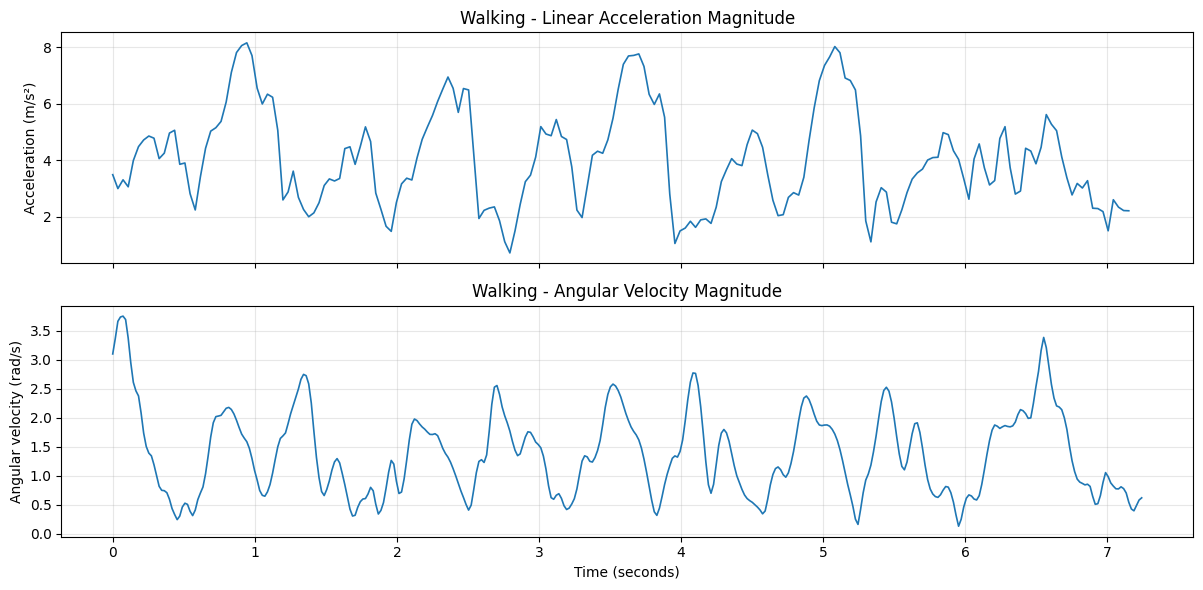

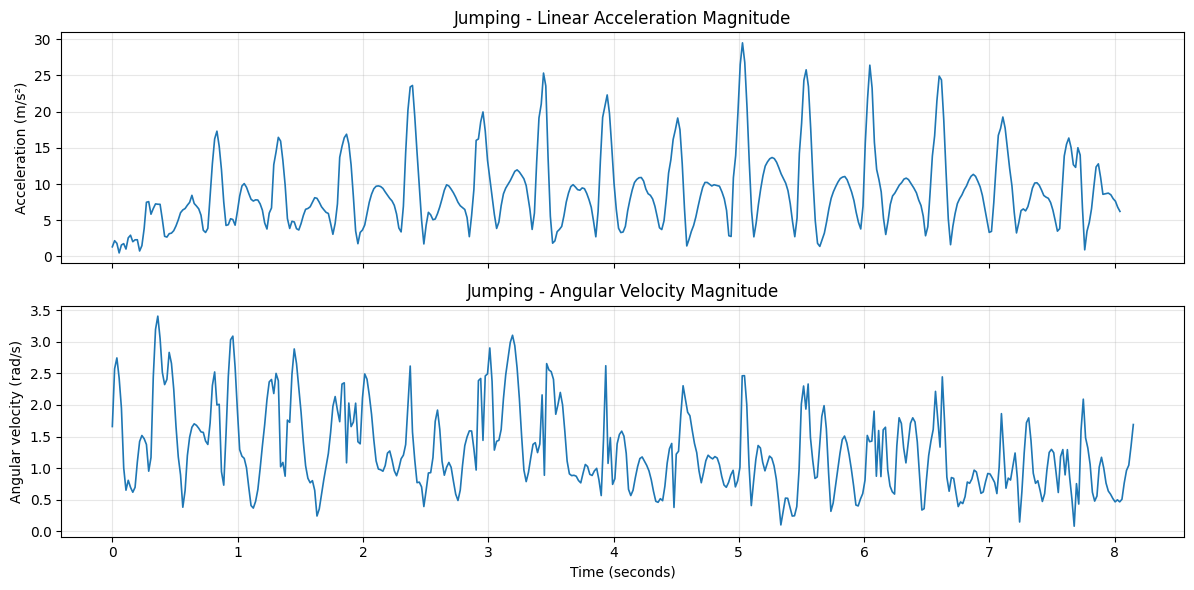

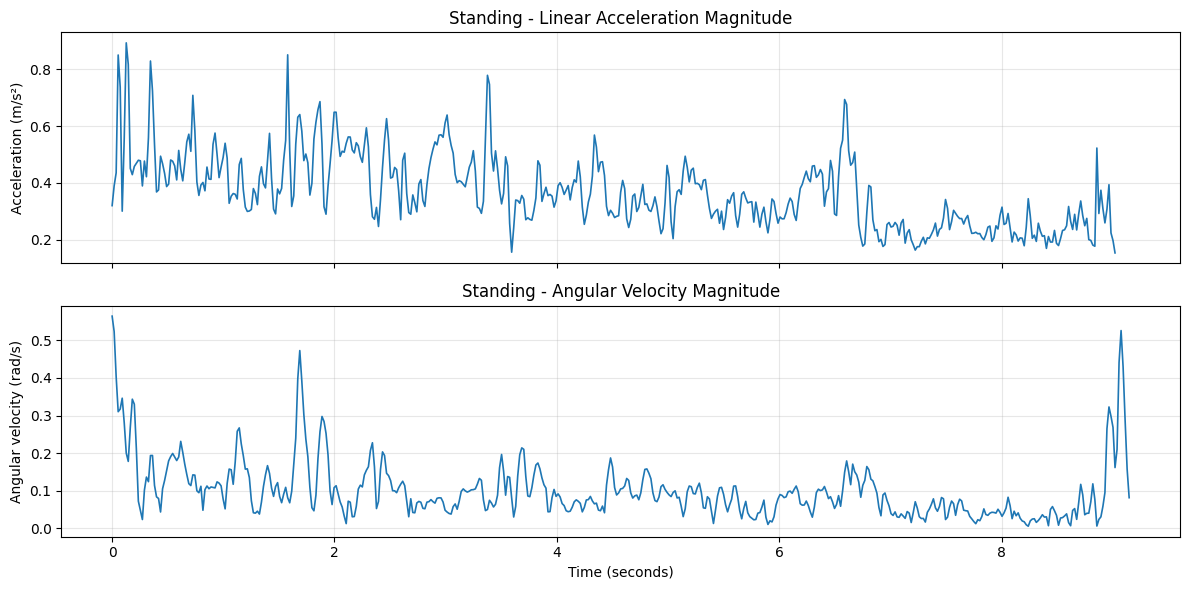

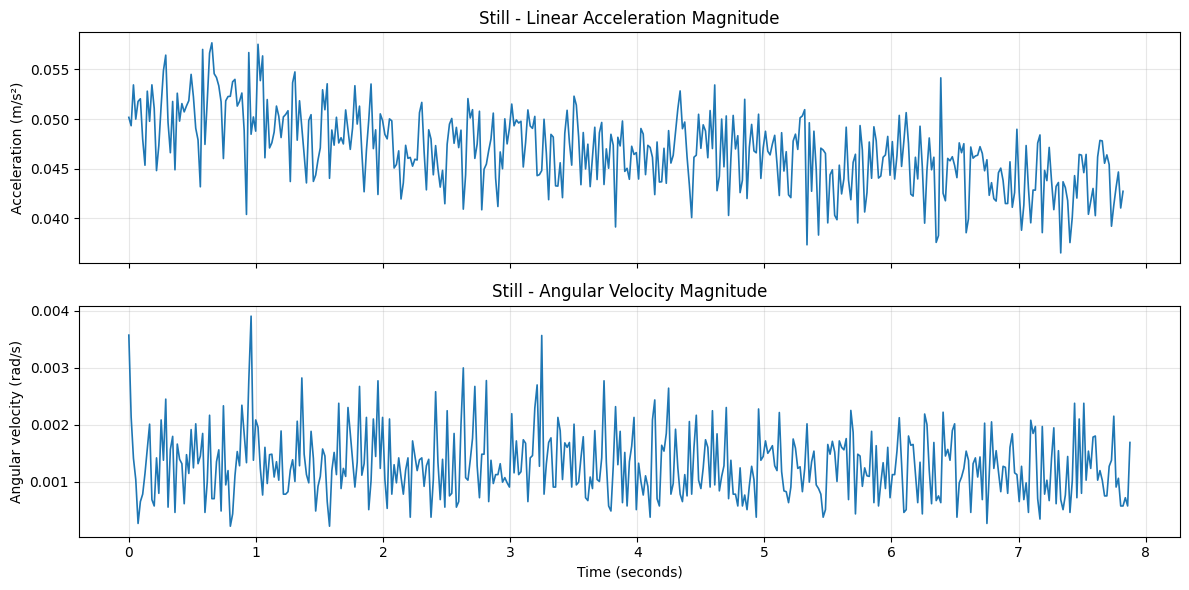

All four plots saved successfully to: /content/drive/MyDrive/Formative2 HMM/Plots


In [ ]:
# Plot the four activities

# Define the Google Drive folder for saving plots
PLOTS_DIR = DATA_DIR.parent / "Plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Select one representative training recording from each activity
sample_recordings = {"Walking": "Walking_01.zip", "Jumping": "Jumping_01.zip", "Standing": "Standing_01.zip", "Still": "Still_02.zip"}

for activity, filename in sample_recordings.items():
    zip_path = DATA_DIR / activity / "Train" / filename
    plot_sensor_signals(zip_path, activity)

print(f"All four plots saved successfully to: {PLOTS_DIR}")

Let's also quantify the differences between the four activities using only training recordings.

In [ ]:
# Select training recordings only
train_quality = quality_df[quality_df["split"] == "Train"].copy()

# Compare overall acceleration intensity
activity_stats = train_quality.groupby("activity").agg(recordings=("filename", "count"), median_rms=("acc_rms", "median"),
                                       maximum_rms=("acc_rms", "max"), median_peak=("acc_peak", "median"), maximum_peak=("acc_peak", "max"))

print("ACCELERATION STATISTICS BY ACTIVITY")
display(activity_stats.round(3))

ACCELERATION STATISTICS BY ACTIVITY


,recordings,median_rms,maximum_rms,median_peak,maximum_peak
activity,,,,,
Jumping,12,9.843,11.871,26.260,41.308
Standing,12,0.381,0.651,1.386,2.969
Still,13,0.049,0.055,0.070,0.222
Walking,13,4.397,7.254,7.544,11.367


## 4. Sensor Synchronization and Resampling

Let's first start by define our preprocessing parameters, and create a synchronization and resampling function

In [ ]:
TARGET_HZ = 25  #Common sampling frequency
CUTOFF_HZ = 8  #Low-pass filter cutoff frequency

# Sensor axes
AXES = ["x", "y", "z"]

print(f"Target sampling frequency: {TARGET_HZ} Hz")
print(f"Low-pass filter cutoff: {CUTOFF_HZ} Hz")
print(f"Time interval between samples: {1 / TARGET_HZ:.3f} seconds")

Target sampling frequency: 25 Hz
Low-pass filter cutoff: 8 Hz
Time interval between samples: 0.040 seconds


**Why 8 Hz?** It is a conservative initial cutoff intended to retain most human movement dynamics while attenuating higher-frequency components before resampling. We will review the resulting plots to check that important jumping and walking patterns are preserved.

In [ ]:
def synchronize_recording(zip_path, target_hz=TARGET_HZ, cutoff_hz=CUTOFF_HZ):
    with zipfile.ZipFile(zip_path, "r") as archive:
        acc = pd.read_csv(archive.open("Accelerometer.csv"))
        gyro = pd.read_csv(archive.open("Gyroscope.csv"))

    start_time = max(acc["seconds_elapsed"].iloc[0], gyro["seconds_elapsed"].iloc[0])
    end_time = min(acc["seconds_elapsed"].iloc[-1], gyro["seconds_elapsed"].iloc[-1])

    if end_time <= start_time:
        raise ValueError(f"No overlapping sensor timestamps: {zip_path.name}")

    duration = end_time - start_time
    time_grid = start_time + np.arange(int(np.floor(duration * target_hz)) + 1) / target_hz
    time_grid = time_grid[time_grid <= end_time]

    synchronized = pd.DataFrame({"time_s": time_grid - start_time})

    for sensor_name, df in [("acc", acc), ("gyro", gyro)]:
        time = df["seconds_elapsed"].to_numpy(dtype=float)
        original_hz = 1 / np.median(np.diff(time))

        if cutoff_hz >= original_hz / 2:
            raise ValueError(f"Filter cutoff exceeds Nyquist frequency: {zip_path.name}")

        sos = butter(6, cutoff_hz, btype="lowpass", fs=original_hz, output="sos")

        for axis in AXES:
            values = df[axis].to_numpy(dtype=float)
            filtered = sosfiltfilt(sos, values)
            synchronized[f"{sensor_name}_{axis}"] = np.interp(time_grid, time, filtered)

    return synchronized

Next, let's test the function on two recordings scenarios: a low-frequency accelerometer recording and a recording where both sensors use approximately 55 Hz.

In [ ]:
# Walking recording with approximately 27.55 Hz accelerometer data
walking_path = DATA_DIR / "Walking" / "Train" / "Walking_01.zip"
walking_processed = synchronize_recording(walking_path)

# Jumping recording with approximately 55.10 Hz sensor data
jumping_path = DATA_DIR / "Jumping" / "Train" / "Jumping_01.zip"
jumping_processed = synchronize_recording(jumping_path)

print("WALKING PROCESSED DATA")
print(f"Shape: {walking_processed.shape}")
display(walking_processed.head())

print("\nJUMPING PROCESSED DATA")
print(f"Shape: {jumping_processed.shape}")
display(jumping_processed.head())

WALKING PROCESSED DATA
Shape: (178, 7)


,time_s,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,2.934740,-1.388709,-1.260505,-0.793904,-0.291714,2.399858
1,0.04,3.062367,-0.153252,-0.415845,-0.495836,-0.212456,1.909821
2,0.08,2.805541,0.691846,-0.860941,-0.261748,-0.076900,1.562714
3,0.12,2.868514,1.247124,-1.511452,-0.108912,-0.008752,1.206878
4,0.16,3.259012,1.633478,-1.855794,-0.071891,0.066796,0.910317



JUMPING PROCESSED DATA
Shape: (202, 7)


,time_s,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,-0.835712,0.918351,-0.475347,1.024861,-2.373801,0.242144
1,0.04,-0.751737,-0.241911,-1.408163,0.308588,-1.093159,0.279514
2,0.08,-0.342017,-0.788381,-1.142206,-0.647229,0.308431,0.336003
3,0.12,0.464004,-1.642443,-0.161250,-0.371325,0.620715,0.091213
4,0.16,0.732660,-2.281660,-0.392065,0.491007,0.936470,-0.028322


Validate the processed recordings: Now let's verify that the output has the frequency and quality we're expecting.

In [ ]:
for activity, df in [("Walking", walking_processed), ("Jumping", jumping_processed)]:
    intervals = np.diff(df["time_s"].to_numpy())
    measured_hz = 1 / np.mean(intervals)

    print(f"\n{activity.upper()}")
    print(f"Number of samples: {len(df)}")
    print(f"Measured frequency: {measured_hz:.2f} Hz")
    print(f"Processed duration: {df['time_s'].iloc[-1]:.2f} seconds")
    print(f"Missing values: {df.isna().sum().sum()}")
    print(f"Infinite values: {np.isinf(df.to_numpy(dtype=float)).sum()}")
    print(f"Unique timestamps: {df['time_s'].is_unique}")

    assert np.allclose(intervals, 1 / TARGET_HZ)
    assert df.isna().sum().sum() == 0
    assert np.isfinite(df.to_numpy(dtype=float)).all()


WALKING
Number of samples: 178
Measured frequency: 25.00 Hz
Processed duration: 7.08 seconds
Missing values: 0
Infinite values: 0
Unique timestamps: True

JUMPING
Number of samples: 202
Measured frequency: 25.00 Hz
Processed duration: 8.04 seconds
Missing values: 0
Infinite values: 0
Unique timestamps: True


Finally, let's visualize the effect of resampling

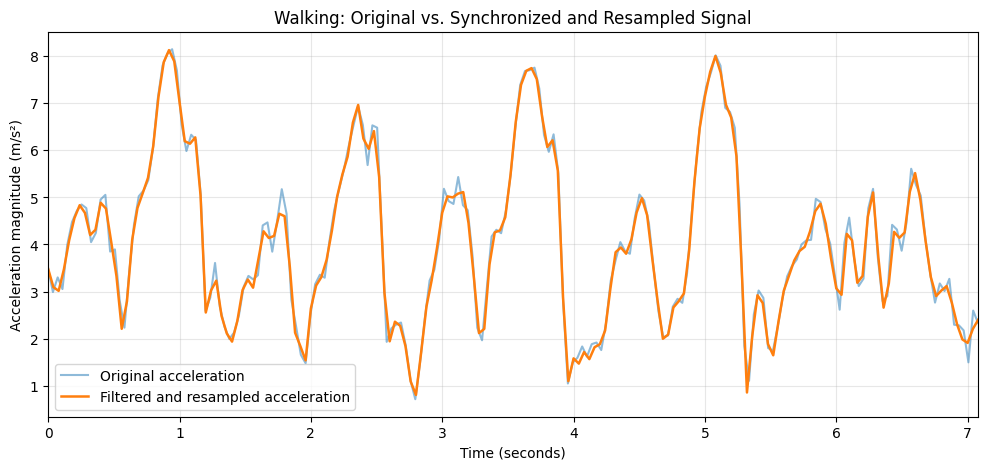

In [ ]:
with zipfile.ZipFile(walking_path, "r") as archive:
    raw_acc = pd.read_csv(archive.open("Accelerometer.csv"))
    raw_gyro = pd.read_csv(archive.open("Gyroscope.csv"))

common_start = max(raw_acc["seconds_elapsed"].iloc[0], raw_gyro["seconds_elapsed"].iloc[0])
raw_time = raw_acc["seconds_elapsed"] - common_start
raw_magnitude = np.linalg.norm(raw_acc[["x", "y", "z"]].to_numpy(), axis=1)
processed_magnitude = np.linalg.norm(walking_processed[["acc_x", "acc_y", "acc_z"]].to_numpy(), axis=1)

plt.figure(figsize=(12, 5))
plt.plot(raw_time, raw_magnitude, label="Original acceleration", alpha=0.5)
plt.plot(walking_processed["time_s"], processed_magnitude, label="Filtered and resampled acceleration", linewidth=1.8)
plt.xlim(0, walking_processed["time_s"].iloc[-1])

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration magnitude (m/s²)")
plt.title("Walking: Original vs. Synchronized and Resampled Signal")

plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(PLOTS_DIR / "Walking_Original_vs_Resampled.png", dpi=300, bbox_inches="tight")
plt.show()

The processed orange signal follows the original blue signal extremely closely.
In particular, the main acceleration peaks are preserved, there is no obvious phase shift, and the small high-frequency fluctuations have been reduced without removing the overall walking pattern. This is exactly the type of result we want from synchronization and resampling.

The difference between the original and processed duration is also normal. We restricted both sensors to their overlapping recording interval and generated samples every 0.04 seconds, without extrapolating beyond the available measurements.

**Conclusion:** Our preprocessing approach is working correctly on both a 27.55 Hz accelerometer recording and a 55.10 Hz recording.

## 5. Preprocess and Save all 58 recordings

We will first process all recordings in memory and validate the results, and then we will save the processed recordings to Google Drive.

In [ ]:
# Store processed recordings and their metadata
processed_recordings = {}
processing_summary = []

for activity in ACTIVITIES:
    for split in ["Train", "Test"]:
        folder = DATA_DIR / activity / split

        for zip_path in sorted(folder.glob("*.zip")):
            processed_df = synchronize_recording(zip_path)

            recording_id = zip_path.stem
            processed_recordings[(activity, split, recording_id)] = processed_df

            processing_summary.append({"activity": activity, "split": split, "recording_id": recording_id, "samples": len(processed_df), "duration_s": processed_df["time_s"].iloc[-1], "sampling_hz": 1 / np.mean(np.diff(processed_df["time_s"]))})

print(f"Successfully processed {len(processed_recordings)} recordings.")


Successfully processed 58 recordings.


In [ ]:
# Convert processing results into a DataFrame
processing_df = pd.DataFrame(processing_summary)

print("PREPROCESSING SUMMARY")
display(processing_df.groupby(["activity", "split"]).agg(recordings=("recording_id", "count"),
        total_samples=("samples", "sum"), total_duration_s=("duration_s", "sum"), mean_sampling_hz=("sampling_hz", "mean")).round(2))

PREPROCESSING SUMMARY


recordings  total_samples  total_duration_s  mean_sampling_hz
activity split                                                               
Jumping  Test            2            437             17.40              25.0
         Train          12           2361             93.96              25.0
Standing Test            2            406             16.16              25.0
         Train          12           2357             93.80              25.0
Still    Test            2            417             16.60              25.0
         Train          13           2442             97.16              25.0
Walking  Test            2            418             16.64              25.0
         Train          13           2375             94.48              25.0

In [ ]:
# Validate every processed recording

# Expected columns after synchronization
EXPECTED_COLUMNS = ["time_s", "acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

# Track quality issues
validation_errors = []

for key, df in processed_recordings.items():
    if df.columns.tolist() != EXPECTED_COLUMNS:
        validation_errors.append(f"{key}: Incorrect columns")

    if df.isna().sum().sum() > 0:
        validation_errors.append(f"{key}: Missing values")

    if not np.isfinite(df.to_numpy(dtype=float)).all():
        validation_errors.append(f"{key}: Infinite or invalid values")

    if not df["time_s"].is_monotonic_increasing or not df["time_s"].is_unique:
        validation_errors.append(f"{key}: Invalid timestamps")

    if len(df) < 2 or not np.allclose(np.diff(df["time_s"]), 1 / TARGET_HZ):
        validation_errors.append(f"{key}: Incorrect sampling interval")

print("FINAL PREPROCESSING VALIDATION")
print(f"Total recordings: {len(processed_recordings)}")
print(f"Recordings with errors: {len(set(validation_errors))}")

if validation_errors:
    for error in validation_errors:
        print(error)
else:
    print("All processed recordings passed validation.")

FINAL PREPROCESSING VALIDATION
Total recordings: 58
Recordings with errors: 0
All processed recordings passed validation.


In [ ]:
# Inspect one processed recording
sample_processed = processed_recordings[("Walking", "Train", "Walking_01")]

print("PROCESSED WALKING RECORDING")
print(f"Shape: {sample_processed.shape}")
display(sample_processed.head(10))

PROCESSED WALKING RECORDING
Shape: (178, 7)


,time_s,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,2.934740,-1.388709,-1.260505,-0.793904,-0.291714,2.399858
1,0.04,3.062367,-0.153252,-0.415845,-0.495836,-0.212456,1.909821
2,0.08,2.805541,0.691846,-0.860941,-0.261748,-0.076900,1.562714
3,0.12,2.868514,1.247124,-1.511452,-0.108912,-0.008752,1.206878
4,0.16,3.259012,1.633478,-1.855794,-0.071891,0.066796,0.910317
5,0.20,3.488488,2.069218,-2.083598,-0.133116,0.071707,0.744243
6,0.24,3.640497,2.556717,-1.893047,-0.127626,0.058775,0.541632
7,0.28,3.603864,2.504242,-1.601535,0.058686,0.057093,0.270210
8,0.32,3.375537,1.898630,-1.627905,0.268204,-0.148825,0.205361
9,0.36,3.756934,1.468237,-1.526337,0.342595,-0.295679,0.196621


Finally, let's save the Processed dataset

In [ ]:
# Define the output directory
PROCESSED_DIR = DATA_DIR.parent / "Processed Data"

# Create the directory structure
for activity in ACTIVITIES:
    for split in ["Train", "Test"]:
        folder = PROCESSED_DIR / activity / split
        folder.mkdir(parents=True, exist_ok=True)

print(f"Processed dataset directory created: {PROCESSED_DIR}")

Processed dataset directory created: /content/drive/MyDrive/Formative2 HMM/Processed Data


In [ ]:
# Save each synchronized recording as a CSV file
saved_files = []

for (activity, split, recording_id), df in processed_recordings.items():
    output_path = PROCESSED_DIR / activity / split / f"{recording_id}.csv"
    df.to_csv(output_path, index=False, float_format="%.12g")
    saved_files.append(output_path)

print(f"Successfully saved {len(saved_files)} processed CSV files.")
print(f"Output directory: {PROCESSED_DIR}")

Successfully saved 58 processed CSV files.
Output directory: /content/drive/MyDrive/Formative2 HMM/Processed Data


In [ ]:
# Create the recordings manifest

manifest_rows = []

for (activity, split, recording_id), df in processed_recordings.items():
    relative_path = Path(activity) / split / f"{recording_id}.csv"
    source_path = Path(activity) / split / f"{recording_id}.zip"

    manifest_rows.append({"recording_id": recording_id, "activity": activity, "split": split, "source_zip": str(source_path), "processed_csv": str(relative_path), "samples": len(df), "duration_s": df["time_s"].iloc[-1], "sampling_hz": TARGET_HZ})

manifest_df = pd.DataFrame(manifest_rows)
manifest_df = manifest_df.sort_values(["activity", "split", "recording_id"]).reset_index(drop=True)

# Save the manifest
manifest_path = PROCESSED_DIR / "recordings_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print(f"Dataset manifest saved: {manifest_path}")
print(f"Manifest entries: {len(manifest_df)}")
display(manifest_df.head(10))

Dataset manifest saved: /content/drive/MyDrive/Formative2 HMM/Processed Data/recordings_manifest.csv
Manifest entries: 58


,recording_id,activity,split,source_zip,processed_csv,samples,duration_s,sampling_hz
0,Jumping_test_01,Jumping,Test,Jumping/Test/Jumping_test_01.zip,Jumping/Test/Jumping_test_01.csv,210,8.36,25
1,Jumping_test_02,Jumping,Test,Jumping/Test/Jumping_test_02.zip,Jumping/Test/Jumping_test_02.csv,227,9.04,25
2,Jumping_01,Jumping,Train,Jumping/Train/Jumping_01.zip,Jumping/Train/Jumping_01.csv,202,8.04,25
3,Jumping_02,Jumping,Train,Jumping/Train/Jumping_02.zip,Jumping/Train/Jumping_02.csv,235,9.36,25
4,Jumping_03,Jumping,Train,Jumping/Train/Jumping_03.zip,Jumping/Train/Jumping_03.csv,177,7.04,25
5,Jumping_04,Jumping,Train,Jumping/Train/Jumping_04.zip,Jumping/Train/Jumping_04.csv,199,7.92,25
6,Jumping_05,Jumping,Train,Jumping/Train/Jumping_05.zip,Jumping/Train/Jumping_05.csv,148,5.88,25
7,Jumping_06,Jumping,Train,Jumping/Train/Jumping_06.zip,Jumping/Train/Jumping_06.csv,207,8.24,25
8,Jumping_07,Jumping,Train,Jumping/Train/Jumping_07.zip,Jumping/Train/Jumping_07.csv,182,7.24,25
9,Jumping_08,Jumping,Train,Jumping/Train/Jumping_08.zip,Jumping/Train/Jumping_08.csv,209,8.32,25


Finally, let's verify that every saved CSV is readable

In [ ]:
verification_errors = []
verified_count = 0

for (activity, split, recording_id), original_df in processed_recordings.items():
    csv_path = PROCESSED_DIR / activity / split / f"{recording_id}.csv"

    if not csv_path.exists():
        verification_errors.append(f"{recording_id}: File missing")
        continue

    saved_df = pd.read_csv(csv_path)

    if saved_df.shape != original_df.shape:
        verification_errors.append(f"{recording_id}: Shape mismatch")
    elif saved_df.columns.tolist() != original_df.columns.tolist():
        verification_errors.append(f"{recording_id}: Column mismatch")
    elif not np.allclose(saved_df.to_numpy(), original_df.to_numpy(), rtol=1e-8, atol=1e-10):
        verification_errors.append(f"{recording_id}: Data mismatch")
    else:
        verified_count += 1

print("SAVED DATASET VERIFICATION")
print(f"Verified recordings: {verified_count}/58")
print(f"Verification errors: {len(verification_errors)}")

if verification_errors:
    for error in verification_errors:
        print(error)
else:
    print("All processed CSV files were saved and reloaded successfully.")

SAVED DATASET VERIFICATION
Verified recordings: 58/58
Verification errors: 0
All processed CSV files were saved and reloaded successfully.
